# 06. Data Augmentation Experiments

Ten eksperyment ma na celu zbadanie wpływu augmentacji danych na skuteczność klasyfikacji zmian skórnych przez model po fine-tuningu. Celem eksperymentu jest zbadanie, czy zastosowanie różnych strategii augmentacji ogranicza przeuczenie oraz poprawia zdolność generalizacji modelu. Badane są całe strategie augmentacji. 

Założenia: te same podziały, checkpoint sprzed FT3, zakres odmrożonych warstw i hiperparametry FT3. Zbiór testowy pozostaje nietknięty.

#### Punkt wyjścia i plan

Punktem startowym jest model baseline (wariant A0), który zostanie wytrenowany w tych samych warunkach co najlepszy model z etapu model_finetuning (FT3), z użyciem trzech strategii augmentacji:

- AUG1 - Łagodna - Odbicia, rotacja w granicach +/- 20 stopni, zoom +/- 5%
- AUG2 - Umiarkowana - Odbicia, rotacja w granicach +/- 90 stopni, zoom +/- 10%, kontrast +/- 10%
- AUG3 - Intensywna - Odbicia, rotacja 0-360 stopni, zoom +/- 15%, kontrast +/-20%, jasność +-10%.

Całość zostanie porównana z modelem bez augmentacji (FT3 z poprzedniego punktu).

## 2. Przygotowanie środowiska

In [25]:
import sys
from pathlib import Path

import tensorflow as tf
from tensorflow.keras import layers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import json

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    balanced_accuracy_score
)

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.image_pipeline import create_dataset
from src.utils import build_confusion_matrix, history_plot, test_aug, build_ft3_model, evaluate_per_class, build_augmentation

In [2]:
print(f"Wersja tensorflow: {tf.__version__}")
print(f"Liczba wykrytych GPU: {len(tf.config.list_physical_devices('GPU'))}")
print(f"Zidentyfikowana karta graficzna: {tf.config.list_physical_devices('GPU')[0]}")

Wersja tensorflow: 2.21.0
Liczba wykrytych GPU: 1
Zidentyfikowana karta graficzna: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


W0000 00:00:1795437531.218887   34245 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


### 2.1. Konfiguracja zmiennych globalnych

In [3]:
IMG_SIZE=(224,224)
BATCH_SIZE=32
SEED = 42
EPOCHS = 50
LEARNING_RATE=1e-5

tf.keras.utils.set_random_seed(SEED)

label_encoder = joblib.load("../dataset/label_encoder.joblib")
class_names = label_encoder.classes_

BASELINE_PATH = Path("../models/best_baseline_a0.keras")
FT3_PATH = Path("../models/FT3_best.keras")
RESULTS_DIR = Path("../models")
OUT_DIR = Path.joinpath(RESULTS_DIR, "06_experiments")

assert BASELINE_PATH.is_file(), (
    f"Nie znaleziono checkpointu: {BASELINE_PATH}\n"
)

### 2.2. Wczytanie danych

In [4]:
train_df = pd.read_csv("../dataset/train_processed.csv")
val_df = pd.read_csv("../dataset/val_processed.csv")

train = create_dataset(
    train_df,
    training=True,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

val = create_dataset(
    val_df,
    training=False,
    BATCH_SIZE=BATCH_SIZE,
    IMG_SIZE=IMG_SIZE
)

print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")

images, labels = next(iter(train))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)

W0000 00:00:1795437531.336525   34245 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795437531.455300   34245 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


Train: 6409
Validation: 1602
Image batch: (32, 224, 224, 3)
Label batch: (32, 7)


### 2.3. Wczytanie punktu odniesienia (FT3)

In [5]:
FT3 = tf.keras.models.load_model(FT3_PATH)
FT3.summary()
baseline_F1macro=FT3.evaluate(val, return_dict=True)['f1_macro']

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,336,242 (39.43 MB)

 Trainable params: 3,138,851 (11.97 MB)

 Non-trainable params: 919,687 (3.51 MB)

 Optimizer params: 6,277,704 (23.95 MB)

... (2 outputs left out)

I0000 00:00:1795437545.567853   34406 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


48/51 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8281 - f1_macro: 0.6110 - loss: 0.5250

E0000 00:00:1795437547.148363   34407 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795437548.190453   34407 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1795437548.710729   34407 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


51/51 ━━━━━━━━━━━━━━━━━━━━ 17s 124ms/step - accuracy: 0.8171 - f1_macro: 0.6819 - loss: 0.5711


## 3. Konfiguracje augmentacji

In [1]:
EXPERIMENTS = ['AUG1', 'AUG2', 'AUG3']

### 3.1. Wizualna kontrola transformacji

In [7]:
sample_batch = next(train.as_numpy_iterator())

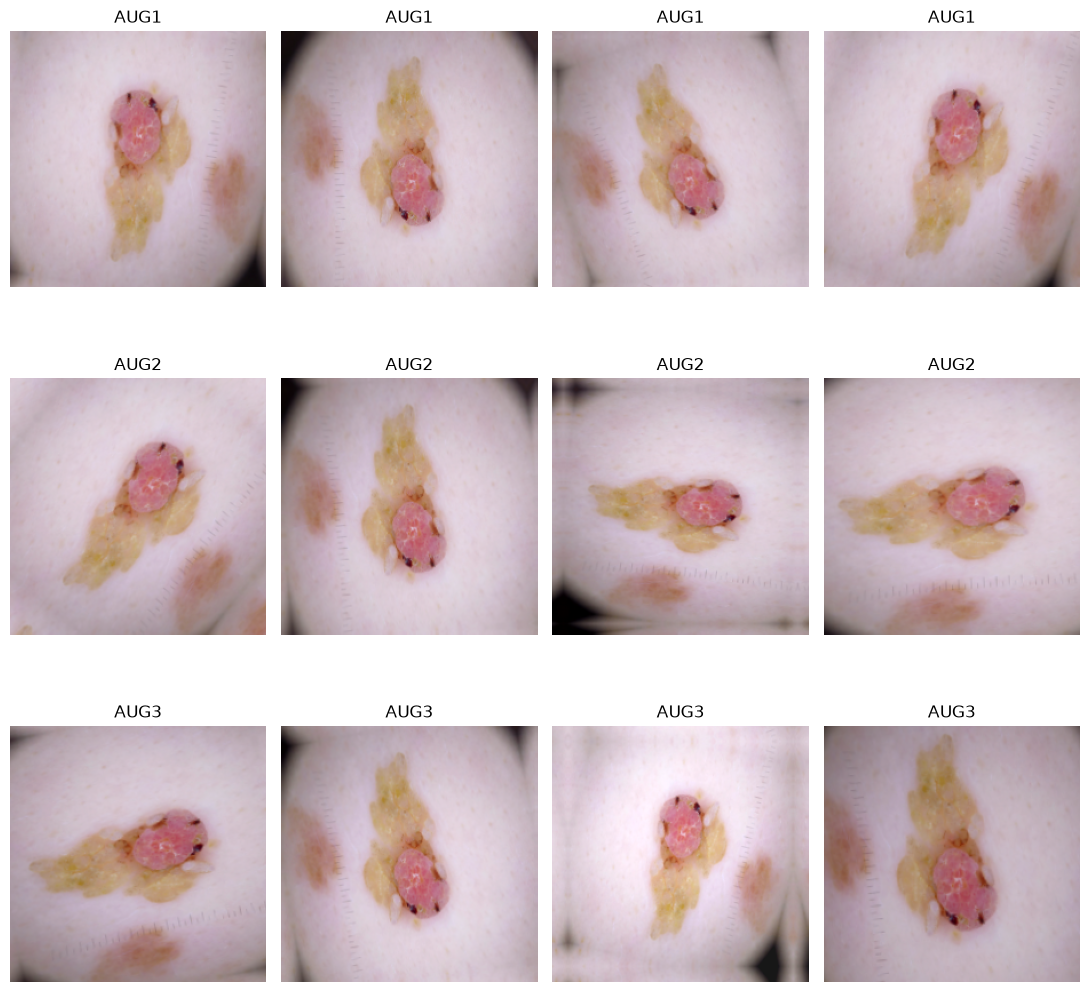

In [8]:
sample_image, _ = next(iter(val))
fig, axes = plt.subplots(3, 4, figsize=(11, 11))
for r, exp_id in enumerate(EXPERIMENTS):
    aug = build_augmentation(exp_id)
    for c in range(4):
        img = aug(sample_image[:1], training=True)[0]
        axes[r, c].imshow(np.clip(img.numpy() / 255, 0, 1))
        axes[r, c].set_title(exp_id)
        axes[r, c].axis('off')
plt.tight_layout()


## 4. Trening

### 4.1. Weryfikacja działania funkcji budującej model FT3

In [9]:
model = build_ft3_model(
    BASELINE_PATH,
    (*IMG_SIZE, 3),
    augmentation=None,
    model_name="FT3_test")
    
model.summary()

Model: "FT3_test"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional (Functional)         │ (None, 7)              │     4,058,538 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 3,138,851 (11.97 MB)

 Non-trainable params: 919,687 (3.51 MB)

### 4.2. Funkcja wykonująca eksperyment

In [10]:
def run_experiment(experiment_id, class_weight=None):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    
    CW = "" if class_weight is None else "CW_"

    model = build_ft3_model(
        BASELINE_PATH,
        (*IMG_SIZE, 3),
        augmentation= build_augmentation(experiment_id),
        model_name=CW+experiment_id
    )

    exp_dir = OUT_DIR / (CW+experiment_id)
    print(exp_dir)
    exp_dir.mkdir(parents=True, exist_ok=True)

    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(exp_dir / 'best.keras'),
            monitor="val_f1_macro",
            mode="max",
            save_best_only=True,
        ),
    
        tf.keras.callbacks.EarlyStopping(
            monitor="val_f1_macro",
            mode="max",
            patience=10,
            restore_best_weights=True,
        )
    ]
    
    history = model.fit(train, validation_data=val, epochs=EPOCHS,
                        callbacks=callbacks, verbose=1, class_weight=class_weight)  
    pd.DataFrame(history.history).to_csv(exp_dir / 'history.csv', index=False)

    results = model.evaluate(
        val,
        return_dict=True,
        verbose=0
    )
    
    metrics = {
        "experiment": experiment_id,
        "f1_macro": float(results["f1_macro"]),
        "accuracy": float(results["accuracy"]),
        "loss": float(results["loss"])
    }
    
    (exp_dir / "metrics.json").write_text(
        json.dumps(metrics, indent=2),
        encoding="utf-8"
    )
    return metrics

In [11]:
results = [run_experiment(exp_id) for exp_id in EXPERIMENTS]

../models/06_experiments/AUG1
Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795437560.824755   34245 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/AUG1_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 53ms/step - accuracy: 0.7720 - f1_macro: 0.5818 - loss: 0.6205 - val_accuracy: 0.7609 - val_f1_macro: 0.5420 - val_loss: 0.6581
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - accuracy: 0.7979 - f1_macro: 0.6265 - loss: 0.5582 - val_accuracy: 0.7453 - val_f1_macro: 0.5766 - val_loss: 0.6618
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.8006 - f1_macro: 0.6493 - loss: 0.5321 - val_accuracy: 0.7591 - val_f1_macro: 0.6026 - val_loss: 0.6349
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.8104 - f1_macro: 0.6613 - loss: 0.5192 - val_accuracy: 0.7647 - val_f1_macro: 0.5930 - val_loss: 0.6292
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 50ms/step - accuracy: 0.8178 - f1_macro: 0.6888 - loss: 0.5013 - val_accuracy: 0.7753 - val_f1_macro: 0.6109 - val_loss: 0.6159
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 43ms/step - accuracy: 0.8178 - f1_macro: 0.6871 - loss: 0.4861 - val_accuracy: 0.7622 - val_f1_macro: 0.5937 -

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795437964.174423   34245 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/AUG2_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.7681 - f1_macro: 0.5594 - loss: 0.6410 - val_accuracy: 0.7628 - val_f1_macro: 0.5680 - val_loss: 0.6546
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.7791 - f1_macro: 0.6052 - loss: 0.5965 - val_accuracy: 0.7584 - val_f1_macro: 0.6006 - val_loss: 0.6355
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.7939 - f1_macro: 0.6254 - loss: 0.5691 - val_accuracy: 0.7709 - val_f1_macro: 0.6266 - val_loss: 0.6134
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.7979 - f1_macro: 0.6278 - loss: 0.5493 - val_accuracy: 0.7528 - val_f1_macro: 0.5780 - val_loss: 0.6436
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.7948 - f1_macro: 0.6134 - loss: 0.5446 - val_accuracy: 0.7728 - val_f1_macro: 0.6271 - val_loss: 0.6122
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.8050 - f1_macro: 0.6616 - loss: 0.5144 - val_accuracy: 0.7566 - val_f1_macro: 0.5992 -

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795438171.403251   34245 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/AUG3_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 57ms/step - accuracy: 0.7619 - f1_macro: 0.5583 - loss: 0.6526 - val_accuracy: 0.7603 - val_f1_macro: 0.6132 - val_loss: 0.6430
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.7773 - f1_macro: 0.5900 - loss: 0.6122 - val_accuracy: 0.7572 - val_f1_macro: 0.6104 - val_loss: 0.6530
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.7802 - f1_macro: 0.5975 - loss: 0.5864 - val_accuracy: 0.7609 - val_f1_macro: 0.5947 - val_loss: 0.6238
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.7875 - f1_macro: 0.6233 - loss: 0.5741 - val_accuracy: 0.7591 - val_f1_macro: 0.5832 - val_loss: 0.6217
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.7961 - f1_macro: 0.6302 - loss: 0.5461 - val_accuracy: 0.7553 - val_f1_macro: 0.6166 - val_loss: 0.6259
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.8011 - f1_macro: 0.6408 - loss: 0.5397 - val_accuracy: 0.7859 - val_f1_macro: 0.6408 -

## 5. Porównywanie wyników

In [12]:
def load_results():
    rows = []
    for id in EXPERIMENTS:
        path = OUT_DIR / id / 'metrics.json'
        if path.exists():
            rows.append(json.loads(path.read_text(encoding='utf-8')))
    return pd.DataFrame(rows)

results = load_results()

results['delta_vs_FT3'] = results['f1_macro'] - baseline_F1macro
display(results.sort_values('f1_macro', ascending=False))



,experiment,f1_macro,accuracy,loss,delta_vs_FT3
0,AUG1,0.652948,0.792759,0.633575,-0.028982
1,AUG2,0.649785,0.777154,0.613378,-0.032145
2,AUG3,0.647561,0.774657,0.609985,-0.034368


### 5.1. Macierze pomyłek

In [13]:
matrixes = {}

for exp_id in EXPERIMENTS:
    cm, disp = build_confusion_matrix(
        model = tf.keras.models.load_model(OUT_DIR / exp_id / 'best.keras'),
        dataset= val,
        class_names=class_names
    )
    matrixes[str(exp_id)] = (cm, disp)

cm_ft3, disp_ft3 = build_confusion_matrix(FT3, val, class_names)

51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step


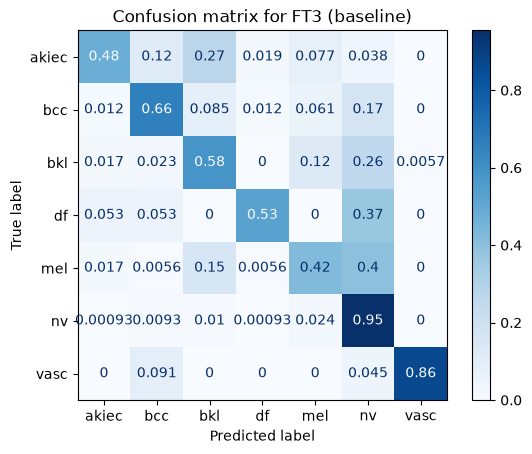

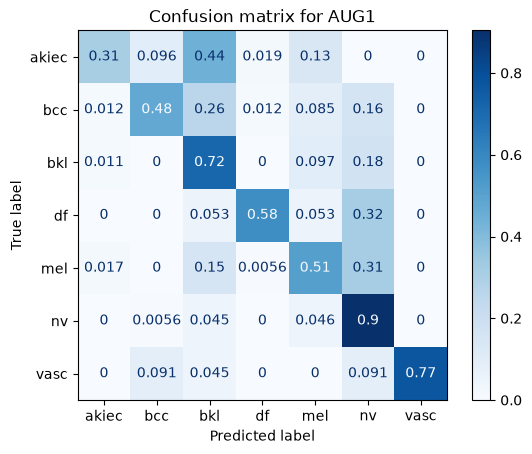

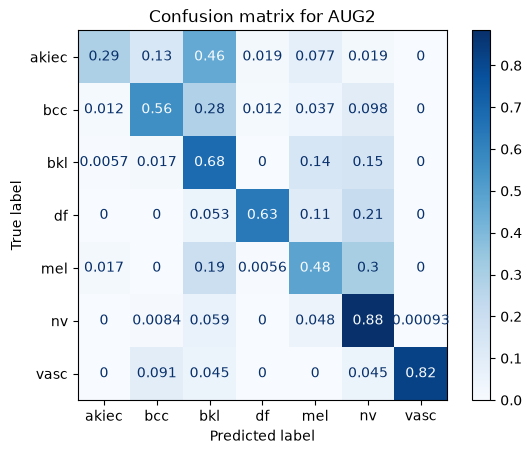

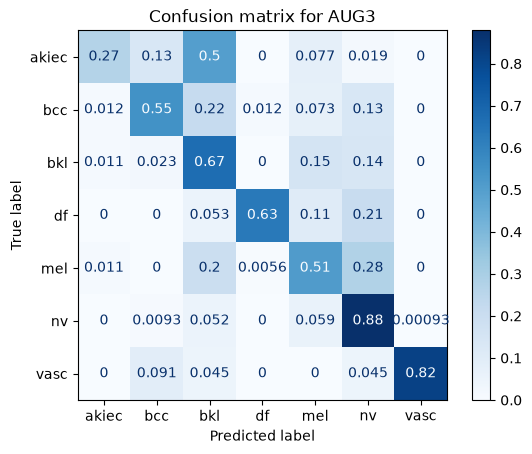

In [14]:
disp_ft3.plot(cmap="Blues")
plt.title("Confusion matrix for FT3 (baseline)")
for exp_id in EXPERIMENTS:
    _ , disp = matrixes[exp_id]
    disp.plot(cmap='Blues')
    plt.title(f"Confusion matrix for {exp_id}")

plt.show()

### 5.2. Krzywe uczenia

EKSPERYMENT AUG1


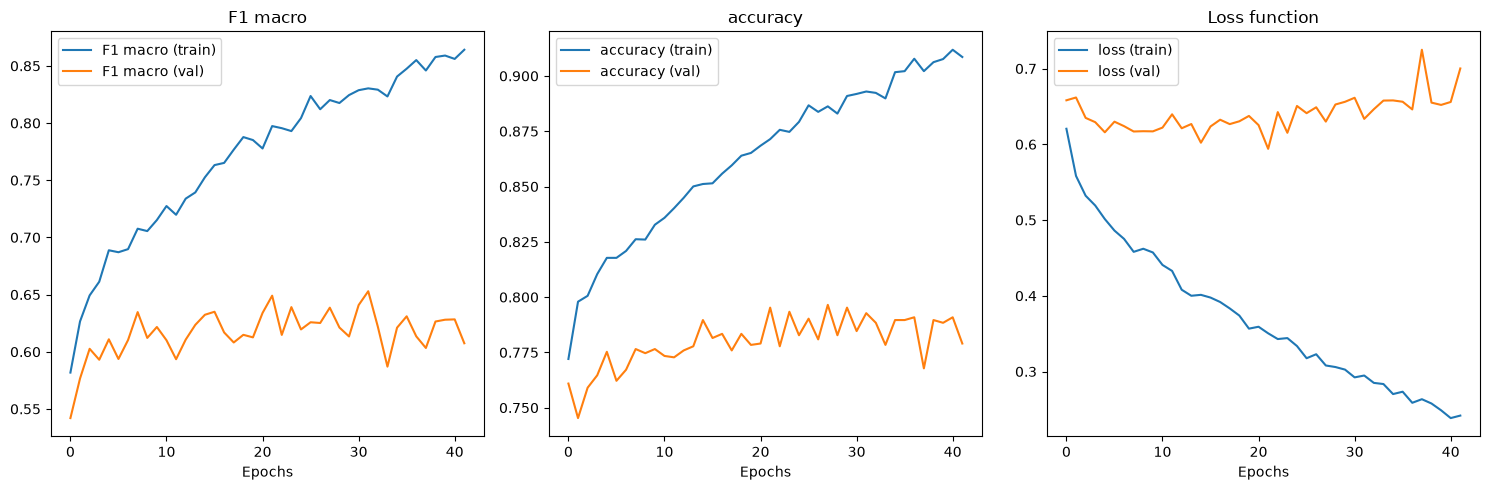

EKSPERYMENT AUG2


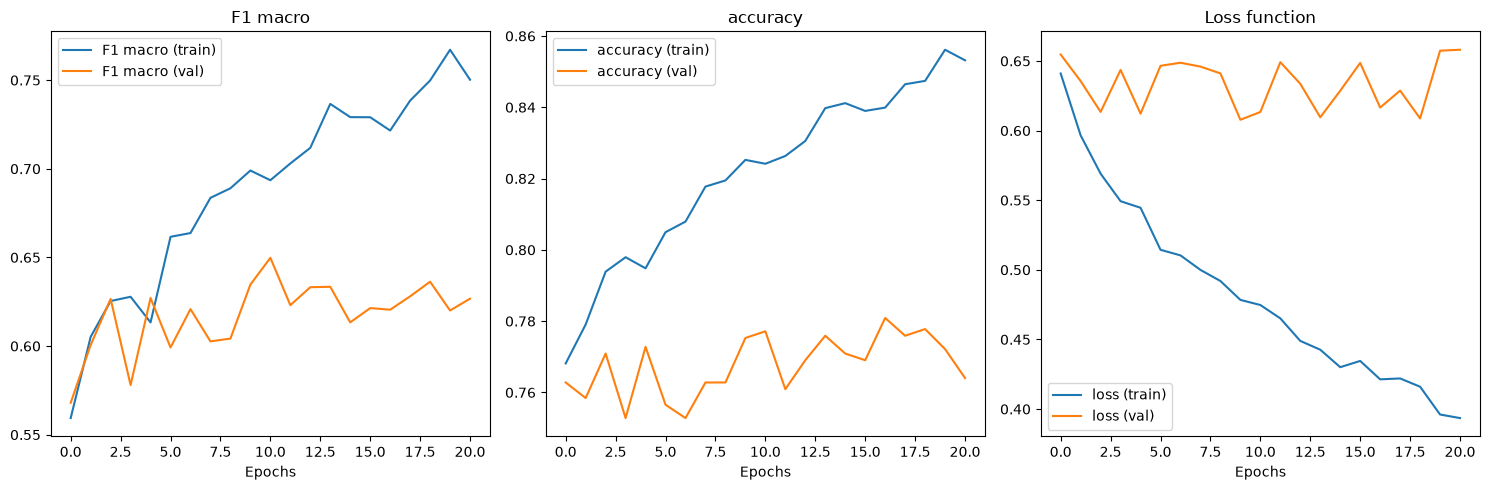

EKSPERYMENT AUG3


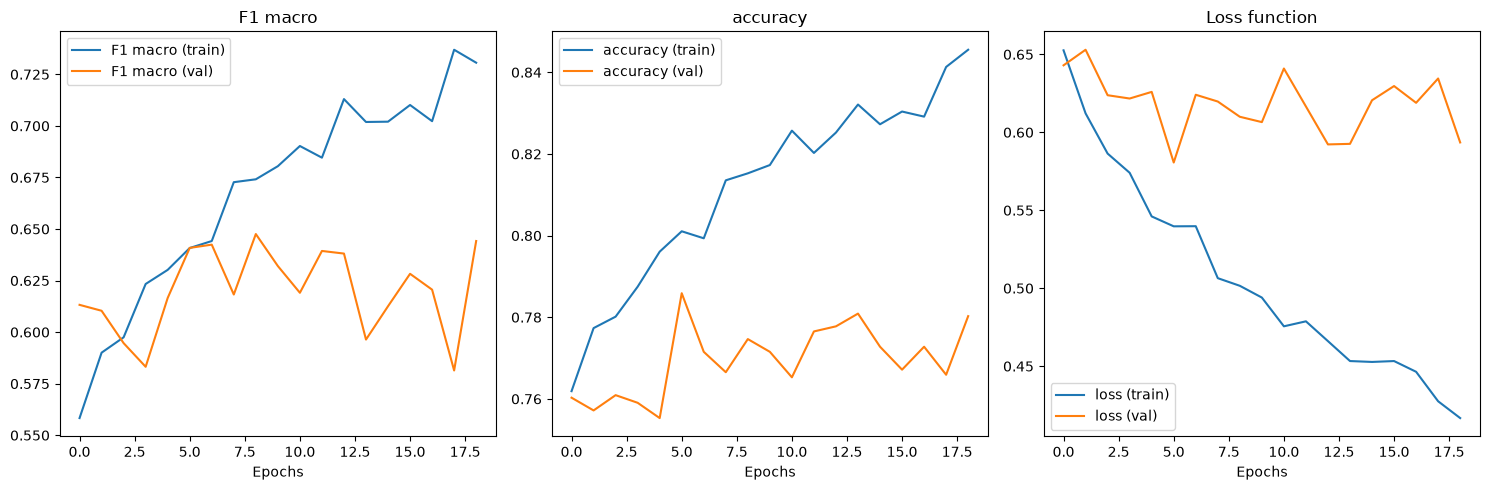

In [15]:
for exp_id in EXPERIMENTS:
    print(f"EKSPERYMENT {exp_id}")
    hist= pd.read_csv(OUT_DIR / exp_id / 'history.csv')
    history_plot(hist)

### 5.3. Zmiana względem baseline

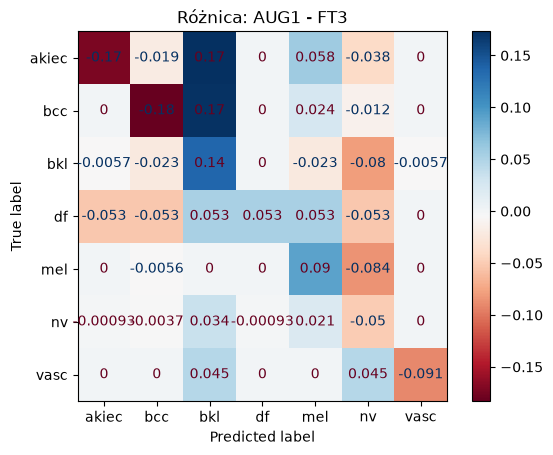

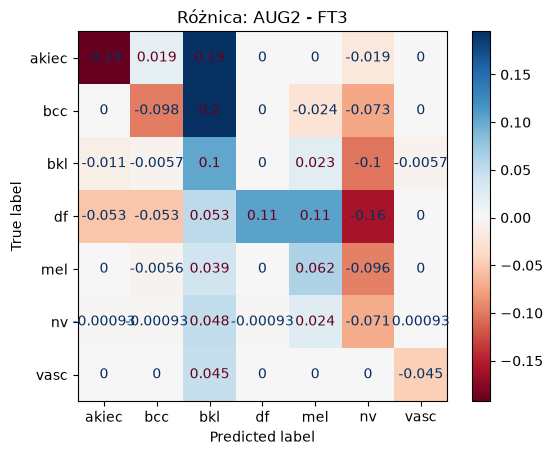

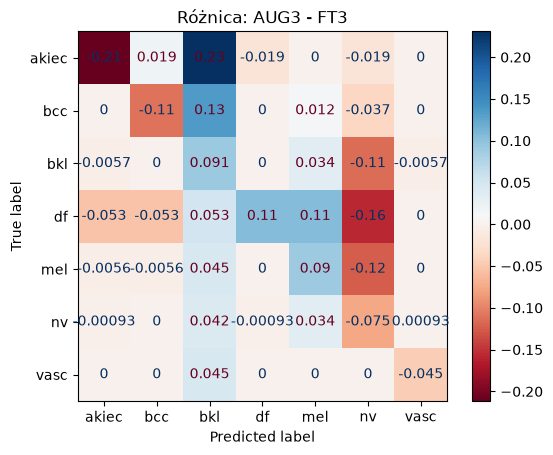

In [16]:
for exp_id in EXPERIMENTS:
    cm , _ = matrixes[exp_id]
    cm_diff = cm - cm_ft3
    disp = ConfusionMatrixDisplay(cm_diff, display_labels=class_names)
    disp.plot(cmap="RdBu")
    plt.title(f"Różnica: {exp_id} - FT3")

plt.show()

## 6. Podsumowanie i wnioski - część bez ważenia klas

- Krzywe uczenia dalej pokazują wyraźną różnicę między treningiem a walidacją - augmentacja nie wyeliminowała przeuczenia.
- Zastosowanie augmentacji wpłynęło na rozkład predykcji pomiędzy klasami, prowadząc zarówno do poprawy, jak i pogorszenia rozpoznawania poszczególnych typów zmian skórnych.
- We wszystkich wariantach augmentacji zaobserwowano wzrost recall klas `mel`, `bkl` i `df`, przy jednoczesnym pogorszeniu recall klas `bcc`, `nv` i `vasc`. Szczególnie istotna jest poprawa recall klasy `mel` o około 10 punktów procentowych, której towarzyszy zmniejszenie częstości błędnego klasyfikowania czerniaka jako `nv`.
- Augmentacja ograniczyła tendencję do przewidywania dominującej klasy `nv`, jednak zwiększyła liczbę błędnych predykcji klasy `bkl` dla części pozostałych klas.
- Wariant AUG3, w przeciwieństwie do AUG1 i AUG2, poprawił również recall klasy `akiec`, co wskazuje na zróżnicowany wpływ intensywności augmentacji na poszczególne klasy.
- Pomimo poprawy recall wybranych klas wszystkie warianty augmentacji uzyskały niższe wartości F1-macro niż model referencyjny. Wskazuje to na występowanie kompromisu pomiędzy poprawą wykrywalności niektórych klas a pogorszeniem pozostałych aspektów klasyfikacji.

## 7. Wznowienie badań po dodaniu mechanizmu ważenia klas.

W poprzednich eksperymentach wykazano, że zastosowanie augmentacji bez ważenia klas prowadziło do obniżenia F1-macro względem modelu referencyjnego FT3. Jednocześnie zaobserwowano poprawę recall niektórych klas mniejszościowych.

Eksperymenty z ważeniem klas również nie przyniosły poprawy F1-macro, jednak ograniczyły tendencję modelu do przypisywania próbek klas mniejszościowych do dominującej klasy nv.

W niniejszym etapie zostanie sprawdzone, czy połączenie obu metod pozwoli poprawić rozróżnianie klas i ograniczyć negatywne efekty obserwowane przy ich niezależnym stosowaniu.

### 7.1. Konfiguracja eksperymentów

Wykorzystanie zostana konfiguracja CW10 z pełnym ważeniem klas, ponieważ uzyskała ona najwyższe F1-macro (0.6847) spośród badanych wariantów ważenia klas.

In [17]:
y_train = train_df["dx_encoded"].to_numpy()

classes = np.arange(len(class_names))

balanced_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

In [18]:
balanced_weights = {
        int(cls): float(weight)
        for cls, weight in zip(classes, balanced_weights)
}

balanced_weights

{0: 4.380724538619275,
 1: 2.782891880156318,
 2: 1.3023775655354604,
 3: 12.542074363992173,
 4: 1.2841114005209378,
 5: 0.2133701767819689,
 6: 10.061224489795919}

### 7.2. Trening

In [19]:
results = [run_experiment(exp_id, balanced_weights) for exp_id in EXPERIMENTS]

../models/06_experiments/CW_AUG1
Epoch 1/50


/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795438388.790355   34245 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CW_AUG1_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.6964 - f1_macro: 0.5182 - loss: 0.9463 - val_accuracy: 0.6255 - val_f1_macro: 0.5164 - val_loss: 0.9844
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.6733 - f1_macro: 0.5273 - loss: 0.7923 - val_accuracy: 0.6180 - val_f1_macro: 0.5236 - val_loss: 1.0027
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 11s 54ms/step - accuracy: 0.6839 - f1_macro: 0.5319 - loss: 0.7812 - val_accuracy: 0.6286 - val_f1_macro: 0.5614 - val_loss: 0.9686
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.6946 - f1_macro: 0.5570 - loss: 0.7271 - val_accuracy: 0.6380 - val_f1_macro: 0.5799 - val_loss: 0.9582
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.6978 - f1_macro: 0.5597 - loss: 0.7265 - val_accuracy: 0.6367 - val_f1_macro: 0.5745 - val_loss: 0.9780
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.7109 - f1_macro: 0.5794 - loss: 0.6933 - val_accuracy: 0.6673 - val_f1_macro: 0.5850

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795438759.912594   34245 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CW_AUG2_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 55ms/step - accuracy: 0.6652 - f1_macro: 0.4883 - loss: 1.0097 - val_accuracy: 0.6286 - val_f1_macro: 0.5440 - val_loss: 0.9721
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 52ms/step - accuracy: 0.6563 - f1_macro: 0.5020 - loss: 0.8695 - val_accuracy: 0.6161 - val_f1_macro: 0.5732 - val_loss: 1.0207
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.6697 - f1_macro: 0.5147 - loss: 0.8249 - val_accuracy: 0.6429 - val_f1_macro: 0.5571 - val_loss: 0.9458
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.6759 - f1_macro: 0.5328 - loss: 0.8053 - val_accuracy: 0.6467 - val_f1_macro: 0.5759 - val_loss: 0.9403
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.6790 - f1_macro: 0.5402 - loss: 0.7589 - val_accuracy: 0.6454 - val_f1_macro: 0.5648 - val_loss: 0.9713
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.6951 - f1_macro: 0.5644 - loss: 0.7297 - val_accuracy: 0.6486 - val_f1_macro: 0.5776 

/home/nagorny/miniconda3/envs/tf_gpu_wsl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1795439241.975359   34245 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CW_AUG3_1/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


201/201 ━━━━━━━━━━━━━━━━━━━━ 17s 56ms/step - accuracy: 0.6648 - f1_macro: 0.4817 - loss: 1.0208 - val_accuracy: 0.6248 - val_f1_macro: 0.5613 - val_loss: 0.9971
Epoch 2/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 46ms/step - accuracy: 0.6405 - f1_macro: 0.4735 - loss: 0.9426 - val_accuracy: 0.6117 - val_f1_macro: 0.5440 - val_loss: 1.0261
Epoch 3/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.6594 - f1_macro: 0.5130 - loss: 0.8653 - val_accuracy: 0.6492 - val_f1_macro: 0.5570 - val_loss: 0.9362
Epoch 4/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.6642 - f1_macro: 0.5164 - loss: 0.8160 - val_accuracy: 0.6442 - val_f1_macro: 0.5803 - val_loss: 0.9489
Epoch 5/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.6798 - f1_macro: 0.5359 - loss: 0.8070 - val_accuracy: 0.6498 - val_f1_macro: 0.5662 - val_loss: 0.9397
Epoch 6/50
201/201 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.6950 - f1_macro: 0.5567 - loss: 0.7453 - val_accuracy: 0.6423 - val_f1_macro: 0.5600 - v

### 7.3. Porównanie wyników

#### 7.3.1. Porównanie F1-macro

In [23]:
results = load_results()

results['experiment'] = "CW_"+results['experiment']
results['delta_vs_FT3'] = results['f1_macro'] - baseline_F1macro
display(results.sort_values('f1_macro', ascending=False))

,experiment,f1_macro,accuracy,loss,delta_vs_FT3
0,CW_AUG1,0.652948,0.792759,0.633575,-0.028982
1,CW_AUG2,0.649785,0.777154,0.613378,-0.032145
2,CW_AUG3,0.647561,0.774657,0.609985,-0.034368


#### 7.3.2. Porównanie metryk poszczególnych klas dla najlepszego modelu

In [27]:
models = {
    "FT3": FT3,
    "CW10": tf.keras.models.load_model(
        OUT_DIR / "CW_AUG3" / "best.keras"
    )
}

reports = {
    name: evaluate_per_class(model, val, class_names)
    for name, model in models.items()
}

In [28]:
comparison = pd.concat({
    name: report[["precision", "recall", "f1-score"]]
        for name, report in reports.items()
    }, axis=1)

display(comparison.round(3))

FT3                      CW10                
      precision recall f1-score precision recall f1-score
akiec     0.735  0.481    0.581     0.767  0.442    0.561
bcc       0.692  0.659    0.675     0.649  0.585    0.615
bkl       0.634  0.580    0.605     0.367  0.812    0.505
df        0.714  0.526    0.606     0.636  0.737    0.683
mel       0.573  0.421    0.485     0.342  0.618    0.440
nv        0.880  0.954    0.916     0.980  0.676    0.800
vasc      0.950  0.864    0.905     0.792  0.864    0.826

### 7.4. Analiza przebiegu uczenia

EKSPERYMENT CW_AUG1


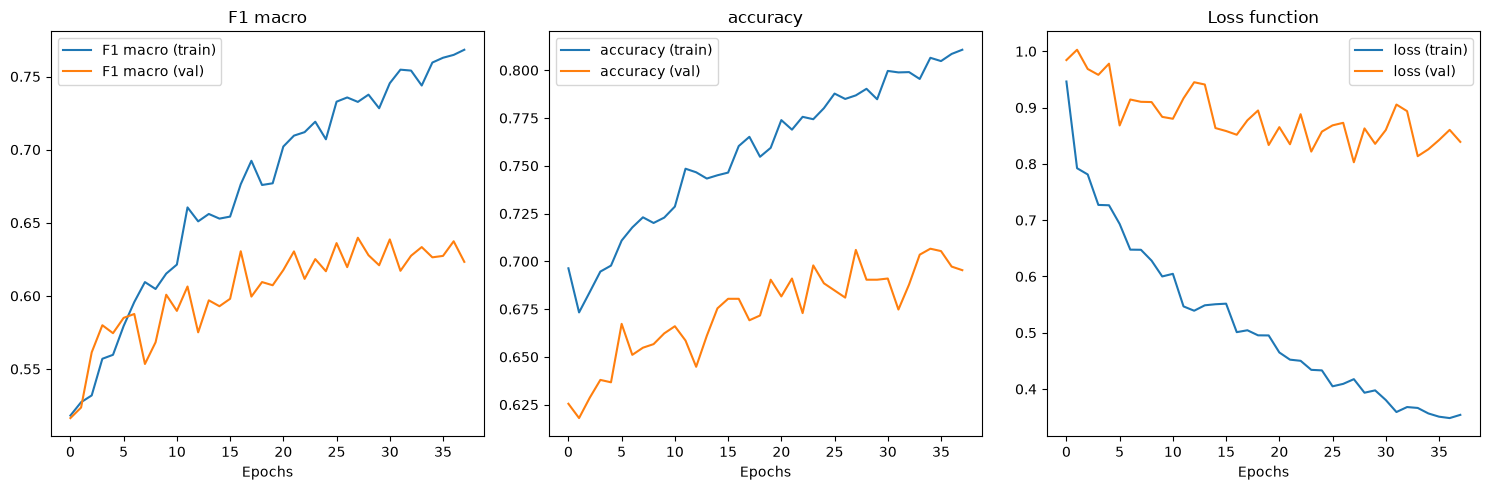

EKSPERYMENT CW_AUG2


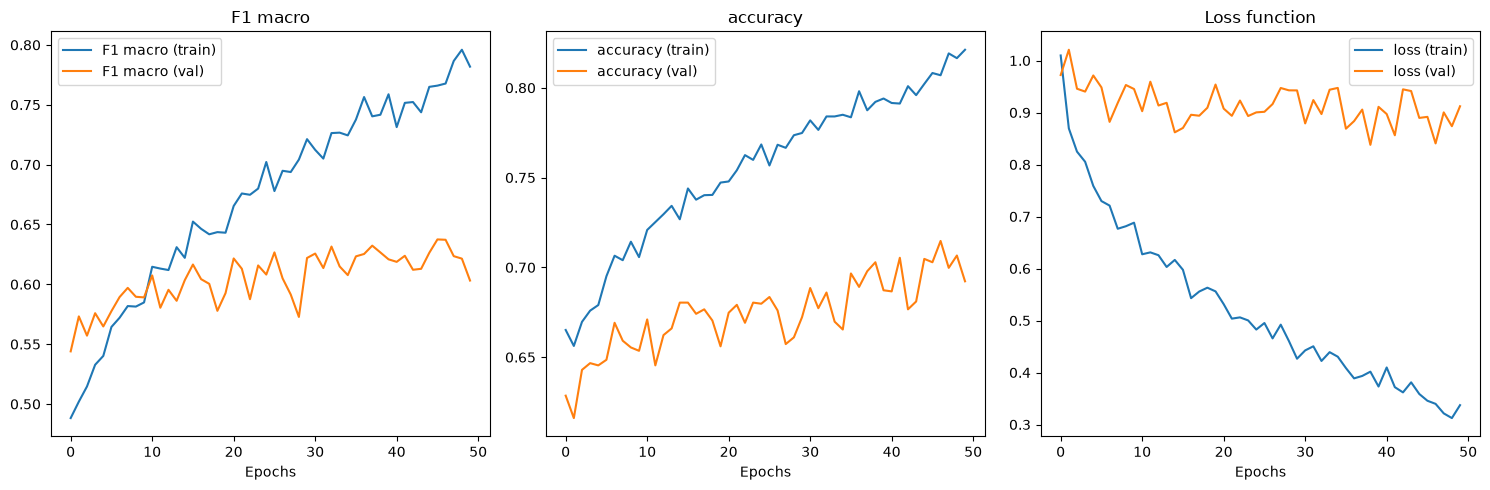

EKSPERYMENT CW_AUG3


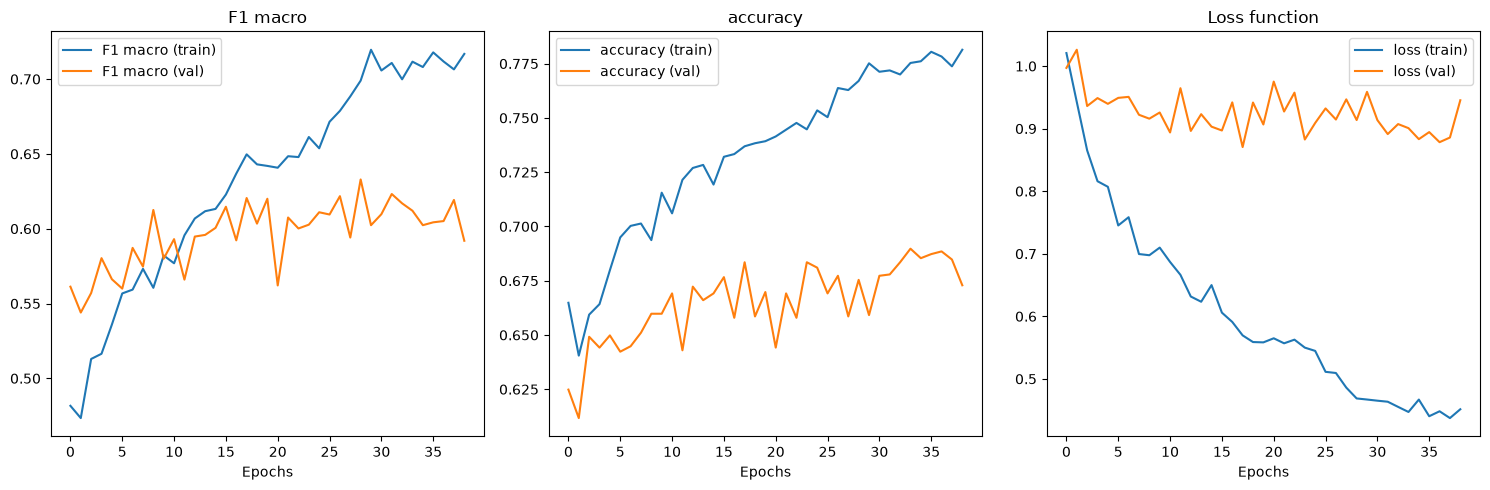

In [29]:
for exp_id in EXPERIMENTS:
    print(f"EKSPERYMENT CW_{exp_id}")
    hist= pd.read_csv(OUT_DIR / ("CW_"+exp_id) / 'history.csv')
    history_plot(hist)

### 7.5. Analiza macierzy pomyłek

In [21]:
matrixes = {}

for exp_id in EXPERIMENTS:
    cm, disp = build_confusion_matrix(
        model = tf.keras.models.load_model(OUT_DIR / ("CW_"+exp_id) / 'best.keras'),
        dataset= val,
        class_names=class_names
    )
    matrixes[str(exp_id)] = (cm, disp)

cm_ft3, disp_ft3 = build_confusion_matrix(FT3, val, class_names)

51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step


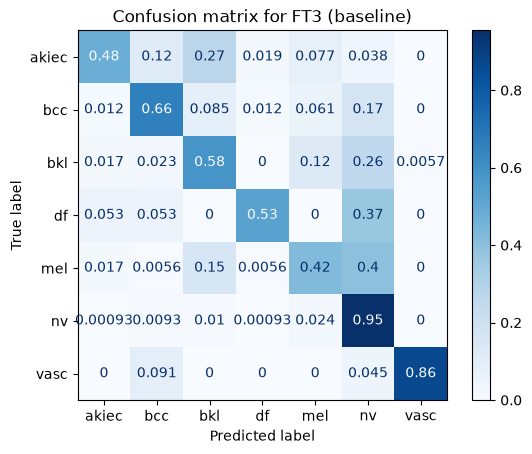

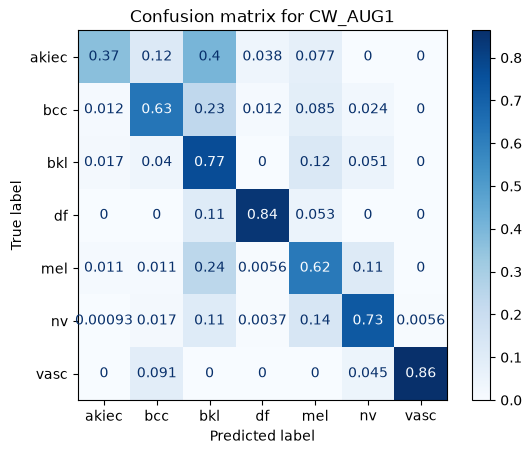

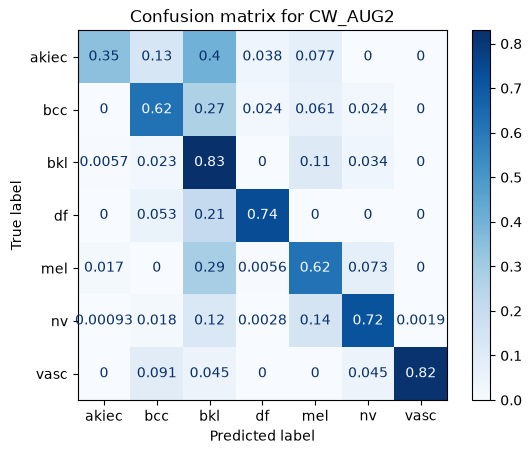

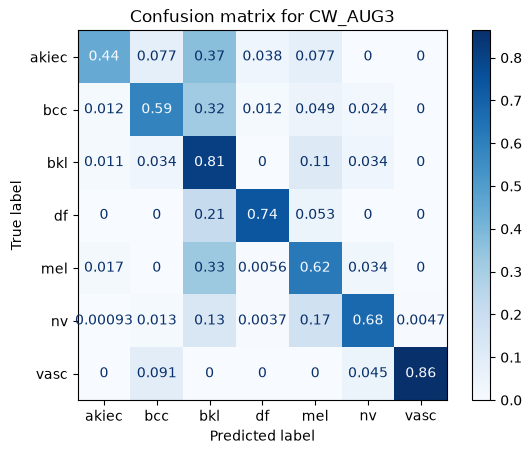

In [30]:
disp_ft3.plot(cmap="Blues")
plt.title("Confusion matrix for FT3 (baseline)")
for exp_id in EXPERIMENTS:
    _ , disp = matrixes[exp_id]
    disp.plot(cmap='Blues')
    plt.title(f"Confusion matrix for CW_{exp_id}")

plt.show()

#### 7.5.1. Analiza macierzy różnic

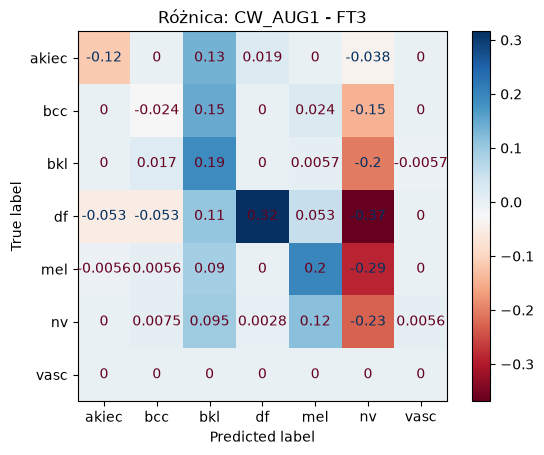

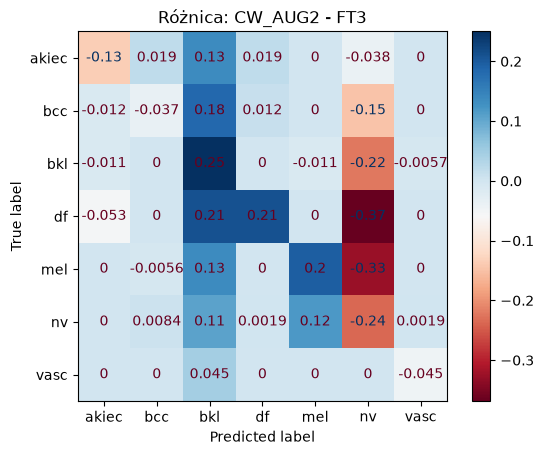

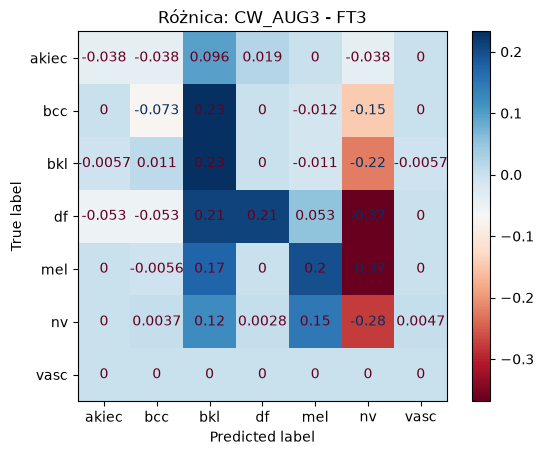

In [32]:
for exp_id in EXPERIMENTS:
    cm , _ = matrixes[exp_id]
    cm_diff = cm - cm_ft3
    disp = ConfusionMatrixDisplay(cm_diff, display_labels=class_names)
    disp.plot(cmap="RdBu")
    plt.title(f"Różnica: CW_{exp_id} - FT3")

plt.show()

## 8. Wnioski końcowe

Zastosowanie augmentacji w połączeniu z ważeniem klas nie przyniosło poprawy F1-macro względem modelu referencyjnego FT3. Zaobserwowano natomiast istotną zmianę charakterystyki predykcji. W szczególności wzrost recall klas `bkl` i `mel` odbywał się kosztem znacznego spadku precision, co wskazuje na zwiększoną liczbę fałszywie dodatnich predykcji tych klas. Jednocześnie nastąpiło pogorszenie recall dominującej klasy `nv`. Wyniki sugerują, że zastosowane metody przede wszystkim przesunęły granice decyzyjne klasyfikatora, zamiast poprawić jego ogólną zdolność rozróżniania zmian skórnych.